<a href="https://colab.research.google.com/github/matteogolfarelli/DataCentricAI/blob/main/Feature%20Selection%20and%20Engineering/Feature_Engineering_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Centric AI — Lab: Feature Engineering

**Course:** Data Centric AI — Module I (Prof. M. Golfarelli)
**Topic:** Feature Engineering (CRISP-DM, step 3 — Data Preparation)

This lab puts into practice the feature engineering techniques of the *Feature Selection and Engineering* slide deck (slides 49–104). We work mainly on the **Titanic** dataset. When an effect is not visible on Titanic we use small **synthetic datasets** built on purpose (loan applicants, delivery orders, daily use of a streaming service), so that we know exactly which relationships hold between the features and the class.

| Part | Content | Data | Slides |
|---|---|---|---|
| 1 | Feature engineering and inductive bias: new features, ratio features, discretization | Titanic, synthetic | 49–89 |
| 2 | Time-based features: circular encoding, temporal leakage, snapshot features from time series | synthetic | 90–104 |

* Cells marked with  contain questions: write your answers in the  cells.
* Questions marked with 🔧 ask you to **change a parameter and re-run a cell**. The parameters are written in CAPITALS at the top of the cell (e.g. `N_BINS = 5`). Do it: the goal is to observe how the choices change the features and the models. Remember to set the parameter back to its original value afterwards, because later cells reuse some results.
* Some cells take up to one minute (the comparison of the engineered features in 1.1 trains about 250 models): the cell description tells you when.

The class attribute of Titanic is always drawn with the same colors: <span style="color:#D55E00">■ **0 = Died**</span> &nbsp; <span style="color:#0072B2">■ **1 = Survived**</span>

## Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer, OneHotEncoder
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
CLASS = "Survived"
PALETTE = {0: "#D55E00", 1: "#0072B2"}
RANDOM_STATE = 42

# the three models used throughout the lab (scaling is part of the model when the model needs it)
def LR():  return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
def KNN(k=15): return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
def RF():  return RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)                    # fast
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)             # more stable: used to compare feature sets
def cv_acc(model, X, y, folds=cv):
    # mean accuracy in cross-validation on the TRAINING set
    return cross_val_score(model, X, y, cv=folds, scoring="accuracy").mean()

As in every ML project, we first put aside a **test set** (20% of the passengers, with the same share of survivors as the whole dataset). Every engineered feature is evaluated with cross-validation on the **training set only**: the test set is kept aside for the final evaluation of the chosen model.

In [2]:
URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(URL)
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df[CLASS], random_state=RANDOM_STATE)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
y_tr, y_te = train_df[CLASS].values, test_df[CLASS].values
print(f"training set: {len(train_df)} passengers   test set: {len(test_df)} passengers   survival rate: {y_tr.mean():.1%}")

training set: 712 passengers   test set: 179 passengers   survival rate: 38.3%


The function `make_candidates` builds the numeric version of the Titanic attributes: one-hot encoding of `Sex` and `Embarked`, missing `Age` filled with the **training** median (`AGE_FILL`). These are the **base features** of Section 1.1.

In [3]:
AGE_FILL = train_df["Age"].median()                                            # learnt on the training set

def make_candidates(d):
    X = pd.DataFrame(index=d.index)
    X["Pclass"] = d["Pclass"]
    X["Sex_female"] = (d["Sex"] == "female").astype(int)
    X["Age"] = d["Age"].fillna(AGE_FILL)
    X["SibSp"], X["Parch"] = d["SibSp"], d["Parch"]
    X["Fare"] = d["Fare"]
    emb = d["Embarked"].fillna("S")
    for port in ["C", "Q", "S"]:
        X[f"Emb_{port}"] = (emb == port).astype(int)
    return X

X_tr, X_te = make_candidates(train_df), make_candidates(test_df)
print(f"{X_tr.shape[1]} numeric features:", list(X_tr.columns))
X_tr.head()

9 numeric features: ['Pclass', 'Sex_female', 'Age', 'SibSp', 'Parch', 'Fare', 'Emb_C', 'Emb_Q', 'Emb_S']


,Pclass,Sex_female,Age,SibSp,Parch,Fare,Emb_C,Emb_Q,Emb_S
0,3,0,28.5,0,0,56.4958,0,0,1
1,2,0,28.5,0,0,0.0000,0,0,1
2,1,0,28.5,0,0,221.7792,0,0,1
3,3,1,18.0,0,1,9.3500,0,0,1
4,2,1,31.0,1,1,26.2500,0,0,1


---
# Part 1 — Feature engineering and inductive bias (slides 49–89)

Feature engineering improves the representation **by adding knowledge** we already have about the problem, or by expressing the data so that the relevant patterns are easier for the model to learn (slide 49). Every new feature carries an **inductive bias**: an assumption about how the target depends on the data (slide 53). If the assumption is right the model generalizes better; if it is wrong it can hide useful patterns.

### Before we start: logistic regression can only model monotone effects

Many engineered features of this lab exist because of one limitation of logistic regression (LR). LR computes the probability of the class as

$$P(Y = 1 \mid x) = \sigma(\beta_0 + \beta_1 x_1 + \dots + \beta_p x_p), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}$$

and σ is an increasing function. Therefore, if we change **one** feature $x_j$ and keep the others fixed, the probability can only **always increase** (if $\beta_j > 0$) or **always decrease** (if $\beta_j < 0$): the effect of every numeric feature is **monotone**. LR cannot say "the probability grows with $x_j$ up to a point and then decreases".

**Example.** On Titanic, survival grows from 30% for passengers travelling alone to 55–73% for families of 2–4 people, and then **falls** to 0–36% for families of 5 or more. The next cell trains an LR on `FamilySize` alone and draws its predicted survival probability next to the observed survival rate: the best LR can do is an almost flat, slowly increasing curve, which is wrong for almost every family size. If instead we encode the family size as three groups (alone / 2–4 / 5 or more) with one-hot encoding, each group gets its own coefficient, i.e. its own survival level, and the non-monotone effect can be represented. Engineering features (groups, bins, interactions, sine/cosine of the hour, …) is the way to give a linear model the shapes it cannot build by itself.

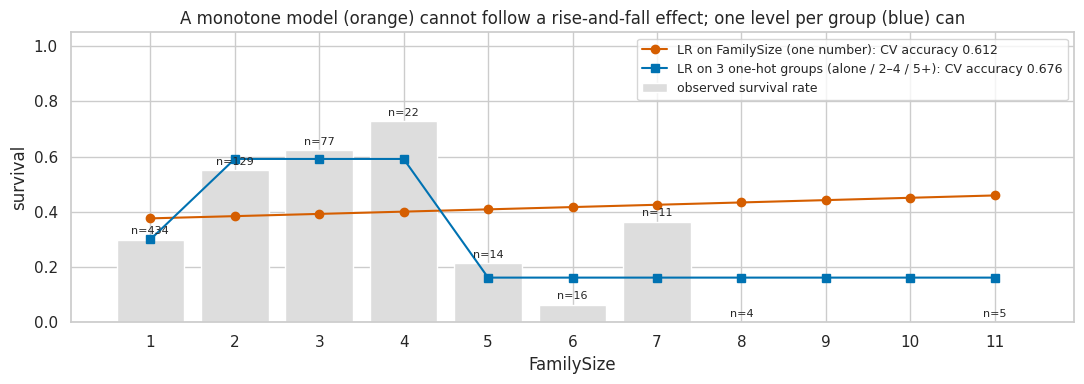

Share of the majority class (always predicting 'died'): 0.617


In [4]:
fs_tr = train_df["SibSp"] + train_df["Parch"] + 1
X_fs = pd.DataFrame({"FamilySize": fs_tr})
X_ft = pd.get_dummies(pd.cut(fs_tr, [0, 1, 4, 20], labels=["alone", "2–4", "5+"]), prefix="Family").astype(int)
lr_fs, lr_ft = LR().fit(X_fs, y_tr), LR().fit(X_ft, y_tr)

sizes = np.arange(1, 12)
obs = pd.DataFrame({"fs": fs_tr, "y": y_tr}).groupby("fs")["y"].agg(["mean", "size"])
grid_ft = pd.get_dummies(pd.cut(pd.Series(sizes), [0, 1, 4, 20], labels=["alone", "2–4", "5+"]), prefix="Family").astype(int)
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(obs.index, obs["mean"], color="#DDDDDD", label="observed survival rate")
for x, (m, n) in obs.iterrows(): ax.text(x, m + 0.02, f"n={int(n)}", ha="center", fontsize=8)
ax.plot(sizes, lr_fs.predict_proba(pd.DataFrame({"FamilySize": sizes}))[:, 1], "o-", color="#D55E00",
        label=f"LR on FamilySize (one number): CV accuracy {cv_acc(LR(), X_fs, y_tr):.3f}")
ax.plot(sizes, lr_ft.predict_proba(grid_ft)[:, 1], "s-", color="#0072B2",
        label=f"LR on 3 one-hot groups (alone / 2–4 / 5+): CV accuracy {cv_acc(LR(), X_ft, y_tr):.3f}")
ax.set_xticks(sizes); ax.set_xlabel("FamilySize"); ax.set_ylabel("survival"); ax.set_ylim(0, 1.05); ax.legend(fontsize=9)
ax.set_title("A monotone model (orange) cannot follow a rise-and-fall effect; one level per group (blue) can")
plt.tight_layout(); plt.show()
print(f"Share of the majority class (always predicting 'died'): {1 - y_tr.mean():.3f}")

## 1.1 New features for Titanic and their inductive bias (slides 49, 53–56, 76–78)

We create meaningful features for Titanic. We start from a **base** set of features (`Pclass`, `Sex_female`, `Age`, `SibSp`, `Parch`, `Fare`, `Emb_C`, `Emb_Q`, `Emb_S`) and add **one engineered feature at a time**. Each one tries to emphasise a behaviour that historians of the Titanic describe:

| New feature | How it is computed |
|---|---|
| `FamilySize` | `SibSp` + `Parch` + 1 |
| `FamilyType` | alone (1) / small (2–4) / large (≥ 5), one-hot |
| `Title` | Mr, Mrs, Miss, Master, Rare extracted from `Name` (e.g. *Braund, **Mr**. Owen Harris*), one-hot |
| `WomanOrChild` | 1 if female, or `Title` = Master, or `Age` < 14 |
| `Sex×Pclass` | the 6 combinations of sex and class, one-hot |
| `LogFare` | log(1 + `Fare`) |
| `FarePerPerson` | `Fare` / `FamilySize` |
| `AgeBand` | child (< 14) / adult (14–59) / senior (≥ 60), one-hot |

Every new feature is computed **from the record of a single passenger**, so it can be computed in production for one new passenger at a time.

**Before running the code**, answer the first question.

###  Question — which technique?
1. The taxonomy of slides 54, 56 and 76 groups the feature engineering techniques into families: *feature construction* (arithmetic and interaction features, aggregation features, temporal features, domain-derived features, features extracted from unstructured data, …) and *feature transformation* (scaling and normalization, distributional transformations, discretization, categorical encoding, …). For each new feature of the table, write the **technique** used to create it. Some features combine two techniques (e.g. a construction followed by an encoding).

###  Your answers
1.

| New feature | Technique |
|---|---|
| `FamilySize` | |
| `FamilyType` | |
| `Title` | |
| `WomanOrChild` | |
| `Sex×Pclass` | |
| `LogFare` | |
| `FarePerPerson` | |
| `AgeBand` | |

The next cell computes, for each new feature, the CV accuracy of logistic regression and random forest with the base features plus the new one, and the change with respect to the base features (Δ). It takes about one minute.

In [ ]:
BASE = ["Pclass", "Sex_female", "Age", "SibSp", "Parch", "Fare", "Emb_C", "Emb_Q", "Emb_S"]

def onehot(s, categories, prefix):
    return pd.get_dummies(pd.Categorical(s, categories=categories), prefix=prefix).astype(int).set_index(s.index)

def add_title(d):
    t = d["Name"].str.extract(r",\s*([^\.]+)\.")[0].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    return t.where(t.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")

def family_size(d): return d["SibSp"] + d["Parch"] + 1

ENGINEERED = {
    "FamilySize": lambda d: pd.DataFrame({"FamilySize": family_size(d)}),
    "FamilyType": lambda d: onehot(pd.cut(family_size(d), [0, 1, 4, 20], labels=["alone", "small", "large"]), ["alone", "small", "large"], "Family"),
    "Title": lambda d: onehot(add_title(d), ["Mr", "Mrs", "Miss", "Master", "Rare"], "Title"),
    "WomanOrChild": lambda d: pd.DataFrame({"WomanOrChild": ((d["Sex"] == "female") | (add_title(d) == "Master") | (d["Age"] < 14)).astype(int)}),
    "Sex×Pclass": lambda d: onehot(d["Sex"] + "_" + d["Pclass"].astype(str), [f"{s}_{c}" for s in ["female", "male"] for c in [1, 2, 3]], "SxC"),
    "LogFare": lambda d: pd.DataFrame({"LogFare": np.log1p(d["Fare"])}),
    "FarePerPerson": lambda d: pd.DataFrame({"FarePerPerson": d["Fare"] / family_size(d)}),
    "AgeBand": lambda d: onehot(pd.cut(d["Age"].fillna(AGE_FILL), [0, 13.99, 59.99, 100], labels=["child", "adult", "senior"]), ["child", "adult", "senior"], "Age"),
}

def with_feature(d, fn=None):
    Xb = make_candidates(d)[BASE]
    return Xb if fn is None else pd.concat([Xb, fn(d)], axis=1)

base_lr, base_rf = cv_acc(LR(), with_feature(train_df), y_tr), cv_acc(RF(), with_feature(train_df), y_tr)
rows = [{"feature set": "base features", "LR": base_lr, "Δ LR": 0.0, "RF": base_rf, "Δ RF": 0.0}]
for name, fn in ENGINEERED.items():
    Xf = with_feature(train_df, fn)
    a_lr, a_rf = cv_acc(LR(), Xf, y_tr), cv_acc(RF(), Xf, y_tr)
    rows.append({"feature set": f"base + {name}", "LR": a_lr, "Δ LR": a_lr - base_lr, "RF": a_rf, "Δ RF": a_rf - base_rf})
fe_res = pd.DataFrame(rows).set_index("feature set")
display(fe_res.style.format("{:+.3f}", subset=["Δ LR", "Δ RF"]).format("{:.3f}", subset=["LR", "RF"])
        .background_gradient(cmap="RdYlGn", subset=["Δ LR", "Δ RF"], vmin=-0.03, vmax=0.03)
        .set_caption("CV accuracy (5-fold × 3) on the training set; Δ = change with respect to the base features"))

The charts show how survival changes with some of the new features (the number on top of each bar is the number of passengers).

In [ ]:
def rate_bars(ax, s, title):
    g = pd.DataFrame({"v": s.values, "y": y_tr}).groupby("v", observed=True)["y"].agg(["mean", "size"])
    bars = ax.bar(g.index.astype(str), g["mean"], color="#9DBFBE", edgecolor="#5E9C9A")
    for b, n in zip(bars, g["size"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02, f"n={n}", ha="center", fontsize=8)
    ax.axhline(y_tr.mean(), ls="--", c="k", lw=1); ax.set_ylim(0, 1.1); ax.set_title(title); ax.tick_params(axis="x", rotation=30)

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
rate_bars(axes[0, 0], family_size(train_df).clip(upper=8), "Survival by FamilySize (8 = 8 or more)")
rate_bars(axes[0, 1], add_title(train_df), "Survival by Title")
rate_bars(axes[0, 2], train_df["Sex"] + " " + train_df["Pclass"].astype(str), "Survival by Sex × Pclass")
rate_bars(axes[1, 0], pd.cut(train_df["Age"].fillna(AGE_FILL), [0, 13.99, 59.99, 100], labels=["child", "adult", "senior"]), "Survival by AgeBand")
for c in [0, 1]:
    sns.kdeplot(train_df.loc[y_tr == c, "Fare"], ax=axes[1, 1], color=PALETTE[c], fill=True, alpha=0.3, cut=0)
    sns.kdeplot(np.log1p(train_df.loc[y_tr == c, "Fare"]), ax=axes[1, 2], color=PALETTE[c], fill=True, alpha=0.3, cut=0)
axes[1, 1].set_title("Fare by class (orange = died, blue = survived)"); axes[1, 2].set_title("LogFare = log(1 + Fare) by class")
axes[1, 2].set_xlabel("LogFare")
plt.tight_layout(); plt.show()

###  Questions — new features for Titanic and their inductive bias
1. For each engineered feature of the table, write the **inductive bias** it introduces: which assumption on the relationship between the original attributes and survival does it express (slide 53)? For example, `FamilySize` assumes that siblings, spouses, parents and children have *the same* effect, since only their total counts.
2. `FamilySize` and `FamilyType` describe the same thing. Which one helps logistic regression more, and why? (Look at the chart *Survival by FamilySize*: is the relationship monotone?)
3. Which features improve logistic regression the most? Why do the same features improve the random forest much less, or even reduce its accuracy? Relate your answer to the chart *Survival by Sex × Pclass* above and to the ability of trees to learn interactions on their own (slide 52: *same model, different features*).
4. `LogFare` changes the distribution of `Fare` but preserves its order. Why can it help logistic regression, while it cannot change anything for a decision tree?
5. `WomanOrChild` encodes the rule "women and children first". What threshold on age does it assume, and what happens to the passengers whose age is missing? Is this bias reasonable?

###  Your answers
1.
2.
3.
4.
5.

## 1.2 A ratio feature under the microscope: `FarePerPerson` (slides 79–89)

In the table of 1.1, `FarePerPerson` = `Fare` / `FamilySize` makes logistic regression slightly **worse** than the base features (negative Δ LR). We check it in two steps: first whether the drop is real, then whether the assumption behind the ratio holds.

**Step 1 — Is the drop real?** A cross-validation accuracy is an average over 15 folds (5 folds × 3 repetitions), and the accuracy changes from fold to fold: the **standard deviation over the folds** tells us how much the estimate fluctuates just because of which passengers end up in each fold. A rule of thumb: a difference between two feature sets that is much **smaller** than this standard deviation is **not significant**, it may be due to chance. The table shows mean and standard deviation of the 15 fold accuracies for the base features, for the base features + `FarePerPerson`, and for the base features **without** `Fare`; the chart shows them as mean ± one standard deviation.

In [ ]:
sets12 = {"base features": with_feature(train_df),
          "base + FarePerPerson": with_feature(train_df, ENGINEERED["FarePerPerson"]),
          "base without Fare": with_feature(train_df).drop(columns="Fare")}
folds12 = {name: cross_val_score(LR(), X, y_tr, cv=cv, scoring="accuracy") for name, X in sets12.items()}
res12 = pd.DataFrame({"CV accuracy (mean of 15 folds)": {n: a.mean() for n, a in folds12.items()},
                      "std over the folds": {n: a.std() for n, a in folds12.items()}})
res12["Δ vs base"] = res12.iloc[:, 0] - res12.iloc[0, 0]
display(res12.style.format("{:.3f}").format("{:+.3f}", subset=["Δ vs base"]).set_caption("Logistic regression, 5-fold × 3 CV on the training set"))

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.errorbar(res12.iloc[:, 0], range(len(res12)), xerr=res12["std over the folds"], fmt="o", color="#5E9C9A", capsize=6, ms=8)
ax.set_yticks(range(len(res12)), res12.index); ax.invert_yaxis()
ax.set_xlabel("CV accuracy (mean ± 1 std over the folds)"); ax.set_title("Are the differences larger than the fold-to-fold variability?")
plt.tight_layout(); plt.show()

###  Questions — Step 1: is the drop real?
* **Variability:** what is the standard deviation of the fold accuracies of the base features?
* **Significance:** is the drop caused by `FarePerPerson` (Δ) larger or smaller than this standard deviation? Is it significant?
* **Information in the fare:** what happens to the accuracy when `Fare` is removed altogether? What does it tell you about the information that the fare adds once `Pclass` and the other base features are known?

###  Your answers
* **Variability:**
* **Significance:**
* **Information in the fare:**

**Step 2 — Does the assumption of the ratio hold?** `Fare` is the price of the **ticket**, and one ticket often covers a whole family. `FarePerPerson` tries to measure the price paid *for each passenger*: it assumes that the price of a ticket grows **in proportion** to the number of family members. Slide 89 lists the checks to make before trusting a ratio.

* The **table** shows, for each family size, the median fare, the median fare per person, the share of 3rd-class passengers and the survival rate.
* The **left chart** shows, inside each class, the median `Fare` by family size; the dashed lines are the fares we would observe if the fare were **proportional** to the family size (fare of a passenger travelling alone × `FamilySize`).
* The **right chart** shows the median `FarePerPerson` by family size; the dashed lines are the value of the passengers travelling alone (if the ratio were a real price per person, the lines would be roughly flat).

Only family sizes with at least 3 passengers in the class are drawn.

In [ ]:
tab = pd.DataFrame({"FamilySize": family_size(train_df).clip(upper=7), "Fare": train_df["Fare"],
                    "FarePerPerson": train_df["Fare"] / family_size(train_df), "Survived": y_tr, "Pclass": train_df["Pclass"]})
summary = tab.groupby("FamilySize").agg(passengers=("Fare", "size"), median_Fare=("Fare", "median"),
                                        median_FarePerPerson=("FarePerPerson", "median"), share_3rd_class=("Pclass", lambda s: (s == 3).mean()),
                                        survival_rate=("Survived", "mean"))
display(summary.round(2).style.set_caption("Training set by FamilySize (7 = 7 or more)"))
print(f"Passengers with Fare = 0: {(train_df['Fare'] == 0).sum()}")
print(f"Correlation with survival:  Fare {np.corrcoef(tab['Fare'], y_tr)[0, 1]:.3f}   FarePerPerson {np.corrcoef(tab['FarePerPerson'], y_tr)[0, 1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for c, col in zip([1, 2, 3], ["#1B4F72", "#5E9C9A", "#B9770E"]):
    s = tab[train_df["Pclass"] == c]
    g = s.groupby("FamilySize").agg(n=("Fare", "size"), Fare=("Fare", "median"), FPP=("FarePerPerson", "median"))
    g = g[g["n"] >= 3]
    axes[0].plot(g.index, g["Fare"], "o-", color=col, label=f"class {c}")
    axes[0].plot(g.index, g.loc[1, "Fare"] * g.index, "--", color=col, lw=1)
    axes[1].plot(g.index, g["FPP"], "o-", color=col, label=f"class {c}")
    axes[1].axhline(g.loc[1, "FPP"], ls="--", color=col, lw=1)
axes[0].set_title("median Fare by FamilySize (dashed = proportional to FamilySize)"); axes[0].set_ylabel("£")
axes[1].set_title("median FarePerPerson by FamilySize (dashed = value of passengers alone)"); axes[1].set_ylabel("£ per person")
for ax in axes: ax.set_xlabel("FamilySize (7 = 7 or more)"); ax.set_yscale("log"); ax.legend()
plt.tight_layout(); plt.show()

###  Questions — Step 2: the checklist of slide 89 for `FarePerPerson`
* **Unit:** what is the unit of measure of `FarePerPerson`?
* **Proportionality:** does `Fare` grow in proportion to `FamilySize` (look at the table and at the dashed lines of the left chart)? As a consequence, what happens to `FarePerPerson` when the family gets larger (right chart)?
* **Denominator:** can `FamilySize` be zero? Is it a reliable count of the people covered by the ticket?
* **Zero values:** 14 passengers have `Fare` = 0. Does `FarePerPerson` = 0 mean "very cheap ticket" for them?
* **Third variable:** look at the share of 3rd-class passengers by family size. Is the low survival of large families explained by the fare, by the class or by the family size? Why is it then risky to interpret the correlation of the ratio with survival (slide 89: *shared denominator*)?
* **Conclusion:** which assumption of `FarePerPerson` fails? Would you keep the feature?

###  Your answers
* **Unit:**
* **Proportionality:**
* **Denominator:**
* **Zero values:**
* **Third variable:**
* **Conclusion:**

## 1.3 Discretization of `Age` (slides 60–65)

Logistic regression can only model a **monotone** effect of `Age` (the older, the more — or the less — likely to survive), while children survive much more than young adults, and the effect then changes little (a non-monotone effect: see *Before we start* at the beginning of Part 1). Discretizing `Age` into bins and one-hot encoding them lets the model learn a **different survival level for each bin**. We compare, inside a logistic regression with `Sex_female` and `Pclass`:
* raw `Age`;
* **equal-width** bins (unsupervised);
* **equal-frequency (quantile)** bins (unsupervised);
* **supervised** bins: the borders are the thresholds of a decision tree trained to predict survival from `Age` alone (slide 65).

All the binnings are learnt **inside the cross-validation** (on the training folds only). The charts are all drawn **on the same age axis**, so that they can be compared:
* first row: the **raw data**. Left: the survival rate by 5-year band of the passengers with known age (bands with at least 5 passengers). Right: the number of training passengers of each age (1-year bars; died and survived stacked); the spike contains the passengers whose age was missing and has been filled with the training median `AGE_FILL`;
* one row for each binning (borders found on the whole training set; dashed vertical lines), with two charts side by side, one bar per bin, as wide as the bin:
  * **left**: the **survival rate** in the bin. The short black segments repeat the 5-year survival rates of the first row, for comparison;
  * **right**: the **number of passengers** in the bin (died and survived stacked).

In [ ]:
N_BINS = 5            # 🔧 number of bins

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
class TreeBinner(BaseEstimator, TransformerMixin):
    # supervised binning: the borders are the split thresholds of a decision tree with n_bins leaves
    def __init__(self, n_bins=5): self.n_bins = n_bins
    def fit(self, X, y):
        t = DecisionTreeClassifier(max_leaf_nodes=self.n_bins, min_samples_leaf=20, random_state=RANDOM_STATE).fit(X, y)
        self.edges_ = np.sort(t.tree_.threshold[t.tree_.feature >= 0])
        self.k_ = len(self.edges_) + 1
        return self
    def transform(self, X):
        idx = np.digitize(np.asarray(X)[:, 0], self.edges_)
        return np.eye(self.k_)[idx]

age_encoders = {"raw Age (continuous)": "passthrough",
                "equal-width bins": KBinsDiscretizer(n_bins=N_BINS, encode="onehot-dense", strategy="uniform"),
                "quantile bins": KBinsDiscretizer(n_bins=N_BINS, encode="onehot-dense", strategy="quantile"),
                "supervised bins (tree)": TreeBinner(n_bins=N_BINS)}
Xa = X_tr[["Sex_female", "Pclass", "Age"]]
rows = []
for name, enc in age_encoders.items():
    pipe = Pipeline([("prep", ColumnTransformer([("age", enc, ["Age"])], remainder="passthrough")),
                     ("sc", StandardScaler()), ("lr", LogisticRegression(max_iter=2000))])
    rows.append({"Age encoding": name, "LR CV accuracy": cv_acc(pipe, Xa, y_tr)})

borders = {"equal-width bins": KBinsDiscretizer(n_bins=N_BINS, encode="ordinal", strategy="uniform").fit(Xa[["Age"]]).bin_edges_[0][1:-1],
           "quantile bins": KBinsDiscretizer(n_bins=N_BINS, encode="ordinal", strategy="quantile").fit(Xa[["Age"]]).bin_edges_[0][1:-1],
           "supervised bins (tree)": TreeBinner(N_BINS).fit(Xa[["Age"]], y_tr).edges_}
colors = {"equal-width bins": "#7F7F7F", "quantile bins": "#ED7D31", "supervised bins (tree)": "#C00000"}
age, known = Xa["Age"].values, train_df["Age"].notna().values
ref_edges = np.arange(0, 85, 5)
ref = pd.Series(y_tr[known]).groupby(pd.cut(age[known], ref_edges), observed=False).agg(["mean", "size"])
ref = ref[ref["size"] >= 5]                                          # 5-year bands with at least 5 passengers

fig, axes = plt.subplot_mosaic([["rawr", "rawn"], ["r0", "n0"], ["r1", "n1"], ["r2", "n2"]], figsize=(17, 14), sharex=True)
ax = axes["rawr"]
ax.bar([iv.mid for iv in ref.index], ref["mean"], width=4.6, color="#BBBBBB")
ax.hlines(ref["mean"], [iv.left for iv in ref.index], [iv.right for iv in ref.index], color="k", lw=1.2)
ax.set_ylim(0, 1.2); ax.set_ylabel("survival rate"); ax.set_title("Raw data: survival rate by 5-year band (known ages, bands with ≥ 5 passengers)", fontsize=10)
ax = axes["rawn"]
ax.hist([age[y_tr == 0], age[y_tr == 1]], bins=np.arange(0, 82, 1), stacked=True, color=[PALETTE[0], PALETTE[1]], label=["died", "survived"])
ax.annotate(f"{(~known).sum()} passengers with missing age,\nfilled with the median {AGE_FILL:g}", xy=(AGE_FILL + 0.6, (age == AGE_FILL).sum() * 0.9),
            xytext=(40, (age == AGE_FILL).sum() * 0.6), arrowprops=dict(arrowstyle="->", color="k", lw=1.2), fontsize=9)
ax.set_ylabel("passengers"); ax.legend(loc="center right"); ax.set_title("Raw data: passengers by age (1-year bars)", fontsize=10)
for k, (name, e) in enumerate(borders.items()):
    edges = np.r_[0, e, 81]
    b_idx = np.digitize(age, e)
    g = pd.DataFrame({"b": b_idx, "y": y_tr}).groupby("b")["y"].agg(["mean", "size", "sum"])
    ax_r, ax_n = axes[f"r{k}"], axes[f"n{k}"]
    for b, r in g.iterrows():
        lo, hi = edges[b], edges[b + 1]; mid, w = (lo + hi) / 2, hi - lo
        ax_r.bar(mid, r["mean"], width=w, color=colors[name], alpha=0.3, edgecolor=colors[name])
        ax_r.text(mid, r["mean"] + 0.03, f"{r['mean']:.0%}", ha="center", va="bottom", fontsize=8 if w > 3 else 6.5)
        ax_n.bar(mid, r["size"] - r["sum"], width=w, color=PALETTE[0], alpha=0.6, edgecolor="k", lw=0.5)
        ax_n.bar(mid, r["sum"], width=w, bottom=r["size"] - r["sum"], color=PALETTE[1], alpha=0.6, edgecolor="k", lw=0.5)
        ax_n.text(mid, r["size"] + 8, f"{r['size']:.0f}", ha="center", va="bottom", fontsize=8 if w > 3 else 6.5)
    for ax in (ax_r, ax_n):
        for x in e: ax.axvline(x, color=colors[name], ls="--", lw=1.5)
    ax_r.hlines(ref["mean"], [iv.left for iv in ref.index], [iv.right for iv in ref.index], color="k", lw=1.2, label="survival by 5-year band (known ages)")
    ax_r.set_ylim(0, 1.2); ax_r.set_ylabel("survival rate"); ax_r.legend(loc="upper right", fontsize=8)
    ax_n.set_ylim(0, 480); ax_n.set_ylabel("passengers")
    ax_r.set_title(f"{name}: survival rate per bin (borders {np.round(e, 1)})", color=colors[name], fontsize=10)
    ax_n.set_title(f"{name}: passengers per bin (orange = died, blue = survived)", color=colors[name], fontsize=10)
for k in ["r2", "n2"]: axes[k].set_xlabel("Age")
axes["r2"].set_xlim(0, 81)
plt.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("Age encoding").round(3)

###  Questions — discretization
1. Which encoding of `Age` gives the best logistic regression? Why do the bins help a *linear* model here?
2. Compare the charts. Where are the data dense, and where does the survival change? How many passengers fall in each bin of the three binnings? Why are the equal-width borders badly placed for this problem? Where do the quantile borders fall, and why (look at the raw data)? Which border of the supervised binning is the most important for survival?
3. The supervised binning uses the class to place the borders. Why must it be learnt inside the cross-validation (or on the training set only)? What would go wrong if the borders were computed on the whole dataset?
4. 🔧 Set `N_BINS = 3` and then `N_BINS = 15`. What happens to the three binnings? Why does a large number of bins risk losing the benefits listed in slide 60 (robustness, interpretability)?
5. Binning implies information loss (slide 60). Which information is lost here, and why can losing it improve the predictions?

###  Your answers
1.
2.
3.
4.
5.

## 1.4 Ratio features: debt-to-income, when is a ratio needed? (slides 83–88)

`FarePerPerson` (1.2) is a ratio whose assumption is contradicted by the data. Here is a case where a ratio is exactly what is needed. The table of slide 83 is shown first, with the **debt-to-income ratio** DTI = Debt / Income. Then we generate 2,000 synthetic loan applicants in which the probability of missing a payment depends **only on DTI** (it grows sharply above 0.45), and compare three models with three feature sets: (`Income`, `Debt`), (`Income`, `Debt`, `DTI`) and `DTI` alone.

In [ ]:
slide82 = pd.DataFrame({"Applicant": list("ABCDEFGH"), "Income": [30, 100, 40, 80, 25, 120, 20, 200],
                        "Debt": [12, 40, 12, 24, 15, 30, 10, 100], "Missed payment": [1, 0, 0, 0, 1, 0, 1, 0]}).set_index("Applicant")
display(slide82.assign(DTI=(slide82["Debt"] / slide82["Income"]).round(2)).T)

rng = np.random.default_rng(RANDOM_STATE)
income = rng.lognormal(np.log(50), 0.6, 2000)                     # k€ per year
dti = rng.beta(2, 3, 2000)                                        # debt / income
cr = pd.DataFrame({"Income": income, "Debt": income * dti})
cr_y = (rng.random(2000) < 1 / (1 + np.exp(-15 * (dti - 0.45)))).astype(int)
sets = {"Income, Debt": ["Income", "Debt"], "Income, Debt, DTI": ["Income", "Debt", "DTI"], "DTI only": ["DTI"]}
cr["DTI"] = cr["Debt"] / cr["Income"]
models = {"Logistic Regression": LR(), "Decision Tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE), "KNN (k=15)": KNN()}
display(pd.DataFrame({m: {s: cv_acc(model, cr[cols], cr_y, cv5) for s, cols in sets.items()} for m, model in models.items()})
        .style.format("{:.3f}").background_gradient(cmap="Greens", axis=None).set_caption("CV accuracy on the synthetic applicants"))

Which attributes do the decision trees use? The charts show the **feature importance** of the three decision trees (depth 3, trained on all the applicants), one per feature set: the impurity-based importance, i.e. the total impurity decrease obtained by the splits on each feature, normalised to sum to 1 (slide 36). Below the charts the splits of each tree are printed (`class: 1` = missed payment).

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.2))
trees = {}
for ax, (s, cols) in zip(axes, sets.items()):
    tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
    acc = cv_acc(tree, cr[cols], cr_y, cv5)
    trees[s] = tree.fit(cr[cols], cr_y)
    imp = pd.Series(tree.feature_importances_, index=cols)
    ax.barh(imp.index, imp.values, color="#9DBFBE", edgecolor="#5E9C9A")
    for k, v in enumerate(imp.values): ax.text(v + 0.02, k, f"{v:.3f}", va="center", fontsize=9)
    ax.set_xlim(0, 1.2); ax.invert_yaxis(); ax.set_xlabel("impurity-based importance")
    ax.set_title(f"Decision tree (depth 3) on {s}\nCV accuracy = {acc:.3f}", fontsize=10)
plt.tight_layout(); plt.show()
for s, tree in trees.items():
    print(f"===== Decision tree on {s} =====")
    print(export_text(tree, feature_names=sets[s], decimals=2))

###  Questions — ratio features
1. Slide 83: who looks riskier between applicants A and B? Can debt be interpreted without income? Which applicants have the same DTI but very different absolute values (slide 87)? Are they really equivalent?
2. In the synthetic applicants, which model needs `DTI` the most? Which models already do well with `Income` and `Debt` alone?
3. Look at the feature importance and at the splits of the three decision trees. Which attribute does the tree on (`Income`, `Debt`) use the most, and how does it try to reproduce the rule "missed payment when DTI > 0.45" with splits on `Income` and `Debt`? Why does it fail with depth 3? When `DTI` is available together with `Income` and `Debt`, which attribute is chosen at the root, and what is left to the other two? Compare the threshold at the root with the 0.45 of the generator.
4. What is the inductive bias of `DTI`? Describe a situation in which it is wrong (slide 88: *Actual Cost = 10,000 + 5 × Unit*).

###  Your answers
1.
2.
3.
4.

---
# Part 2 — Time-based features (slides 90–104)

## 2.1 Circular features: hour of the day (slides 93–98)

A delivery company wants to estimate the probability that an order is delivered **late** from the **hour of the order**. Late deliveries are frequent at night, when few couriers are available: the risk peaks around 1:00 and is low during the day. We generate 3,000 orders and compare three models of the hour:
* `hour` as a number from 0 to 23, with logistic regression;
* the **sine/cosine encoding** `hour_sin` = sin(2π·hour/24), `hour_cos` = cos(2π·hour/24) (slide 94), with logistic regression;
* `hour` as a number, with a **decision tree** of depth `TREE_DEPTH`.

### How do we measure the quality of the models? The ROC AUC

Only about 23% of the orders are late. With such a minority class, **accuracy** is misleading: a model that always answers "on time" is right 77% of the times, yet it is useless. Moreover, the company does not need a yes/no answer but the **predicted risk** of each order (e.g. to assign extra couriers to the riskiest ones): what matters is whether the model **ranks** the late orders above the on-time ones.

The **ROC AUC** (*Area Under the ROC Curve*) measures exactly this:

> take **every pair** made of one late order and one on-time order: the AUC is the **fraction of pairs in which the late order receives the higher predicted risk** (a tie counts ½).

* AUC = 1: every late order has a higher risk than every on-time order (perfect ranking);
* AUC = 0.5: the ranking is no better than chance (e.g. a model that gives the same risk to every order);
* AUC < 0.5: the ranking is upside down.

**The ROC curve, step by step.** Sort the orders from the highest to the lowest predicted risk and walk down the list, one order at a time, drawing a path that starts at (0, 0):
* each **late** order moves the path **up** by 1 / (number of late orders);
* each **on-time** order moves the path **right** by 1 / (number of on-time orders).

The path ends at (1, 1) and is the **ROC curve**. A perfect model meets all the late orders first: the path goes straight up and then right, and the area under it is 1. A model that ranks at random mixes the two kinds of orders: the path stays close to the diagonal, area 0.5. The **area under the curve is exactly the share of correctly ordered pairs**: every horizontal step (one on-time order) adds a column whose height is the share of late orders ranked **above** that on-time order.

The two axes have standard names. If we stopped the walk at some point and flagged as "late" all the orders met so far, the y coordinate would be the share of late orders correctly flagged (**true positive rate**) and the x coordinate the share of on-time orders wrongly flagged (**false positive rate**).

The next cell computes the AUC for a toy example with 8 orders: 3 late (L1–L3) and 5 on time (O1–O5). The left chart is the ranking (the walk goes from left to right); the right chart is the path it draws, with the same order names.

In [ ]:
toy = pd.DataFrame({"order": ["L1", "L2", "L3", "O1", "O2", "O3", "O4", "O5"],
                    "late": [1, 1, 1, 0, 0, 0, 0, 0],
                    "predicted risk": [0.90, 0.60, 0.35, 0.70, 0.40, 0.30, 0.20, 0.10]}).set_index("order")
L_toy, O_toy = toy.loc[toy["late"] == 1, "predicted risk"], toy.loc[toy["late"] == 0, "predicted risk"]
pairs = pd.DataFrame([["✓" if l > o else "½" if l == o else "✗" for o in O_toy] for l in L_toy],
                     index=[f"{i} (risk {r:.2f})" for i, r in L_toy.items()], columns=[f"{i} ({r:.2f})" for i, r in O_toy.items()])
display(pairs.style.set_caption("Every pair (late order = row, on-time order = column): ✓ = the late order has the higher predicted risk"))
correct = (pairs == "✓").values.sum() + 0.5 * (pairs == "½").values.sum()
print(f"Correctly ranked pairs: {correct:g} out of {pairs.size}  →  AUC = {correct / pairs.size:.3f}")
print(f"roc_auc_score gives the same value: {roc_auc_score(toy['late'], toy['predicted risk']):.3f}")
print(f"A model that gives the same risk to every order: AUC = {roc_auc_score(toy['late'], np.full(len(toy), 0.5)):.3f}"
      f"   (while 'always on time' has accuracy {(toy['late'] == 0).mean():.3f})")

ranked = toy.sort_values("predicted risk", ascending=False)
n_late, n_ok = int(toy["late"].sum()), int((1 - toy["late"]).sum())
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
for k, (name, r) in enumerate(ranked.iterrows(), start=1):
    col = "#D55E00" if r["late"] else "#0072B2"
    ax.scatter(k, 0, s=600, color=col, zorder=3)
    ax.text(k, 0, name, ha="center", va="center", color="white", fontsize=10, fontweight="bold", zorder=4)
    ax.text(k, 0.35, f"risk {r['predicted risk']:.2f}", ha="center", fontsize=9)
    ax.text(k, -0.45, f"↑ {1}/{n_late}" if r["late"] else f"→ {1}/{n_ok}", ha="center", fontsize=11, color=col)
ax.set_xlim(0.3, len(toy) + 0.7); ax.set_ylim(-0.8, 0.7); ax.set_yticks([])
ax.set_xticks(range(1, len(toy) + 1)); ax.set_xlabel("position in the ranking (1 = highest predicted risk)")
ax.set_title("1) Rank the orders by predicted risk (orange = late, blue = on time)\nand walk from left to right: late → step up, on time → step right")
ax = axes[1]
x, y, pts = 0.0, 0.0, [(0.0, 0.0, "start")]
for name, r in ranked.iterrows():
    if r["late"]:
        y += 1 / n_late
    else:
        ax.fill_between([x, x + 1 / n_ok], 0, y, color="#0072B2", alpha=0.12)
        ax.text(x + 0.5 / n_ok, y / 2, f"{round(y * n_late)}/{n_late}", ha="center", va="center", fontsize=10)
        x += 1 / n_ok
    pts.append((x, y, name))
ax.plot([p[0] for p in pts], [p[1] for p in pts], "o-", color="#D55E00", lw=2)
for px, py, name in pts[1:]:
    ax.annotate(name, (px, py), textcoords="offset points", xytext=(-14, 4), fontsize=9, fontweight="bold")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="random ranking (area 0.5)")
ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.1)
ax.set_xlabel("share of on-time orders met so far (false positive rate)")
ax.set_ylabel("share of late orders met so far\n(true positive rate)")
ax.set_title(f"2) The ROC curve is the path of the walk. Each column = late orders\nranked above that on-time order; area = {correct:g}/{pairs.size} = {correct / pairs.size:.2f} = AUC", fontsize=10)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### The experiment: which features does each model receive?

Every order has a single raw attribute, the **hour** at which it was placed (an integer from 0 to 23). From it we build two different **feature sets**, i.e. two different ways of showing the same information to the model:

> **Feature set A — the raw hour (1 column)**
>
> * *Intuitively:* the hour is a position on a **ruler** from 0 to 23. On a ruler 23:00 and 0:00 are at the two opposite ends, 23 units apart, although they are only one hour apart in reality.
> * *Formally:* $x = h$, with $h \in \{0, 1, \dots, 23\}$ → column `hour`.
>
> **Feature set B — the sine/cosine encoding (2 columns, slide 94)**
>
> * *Intuitively:* the hour is a position on a **clock face** (a 24-hour clock with 0:00 at the top, 6:00 on the right, 12:00 at the bottom, 18:00 on the left). Each hour becomes a point described by two coordinates, its horizontal and its vertical position on the clock. On the clock 23:00 and 0:00 are neighbours, as in reality.
> * *Formally:* the hour is first converted into an angle $\theta = 2\pi h / 24$, then into the two coordinates of the corresponding point on the unit circle: $x_1 = \sin\theta$ → column `hour_sin`, $x_2 = \cos\theta$ → column `hour_cos`. Both are numbers between −1 and 1; the pair $(x_1, x_2)$ identifies the hour uniquely (one coordinate alone would not: sin is the same for 3:00 and 9:00).

The three models compared below are:

| Model | Features it receives | What it can compute as a function of the hour |
|---|---|---|
| Logistic regression on the raw hour | set A: `hour` | $P(\text{late}) = \sigma(\beta_0 + \beta_1 h)$: a **monotone** curve, always increasing or always decreasing from 0:00 to 23:00 |
| Logistic regression on sin/cos | set B: `hour_sin`, `hour_cos` | $P(\text{late}) = \sigma(\beta_0 + \beta_1 \sin\theta + \beta_2 \cos\theta) = \sigma(\beta_0 + R\cos(\theta - \varphi))$: a smooth **bump** around a peak hour φ, which can extend across midnight |
| Decision tree of depth `TREE_DEPTH` on the raw hour | set A: `hour` | splits of the form "hour ≤ t": a **step function**, constant on intervals of consecutive hours |

Note that the decision tree receives the **same** feature as the first logistic regression: the difference between them is due to the model, while the difference between the two logistic regressions is due to the features.

The next cell generates the orders and **builds the two feature sets** (look for the block marked `FEATURES`); it shows the values of the features for some hours and draws the 24 hours on the clock face of feature set B.

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
hour = rng.integers(0, 24, 3000)                                                # the raw attribute of each order
circ_dist = lambda a, b: np.minimum(np.abs(a - b), 24 - np.abs(a - b))          # circular distance in hours (slide 93)
p_late = 0.08 + 0.55 * np.exp(-circ_dist(hour, 1) ** 2 / (2 * 2.5 ** 2))         # true risk: peak at 1:00
late = (rng.random(3000) < p_late).astype(int)                                  # the class: 1 = late delivery

# ============================== FEATURES ==============================
def hour_features(h):
    h = np.asarray(h)
    theta = 2 * np.pi * h / 24                                   # hour → angle on the 24-hour clock
    return pd.DataFrame({"hour": h,                              # feature set A: the raw hour, 0–23
                         "hour_sin": np.sin(theta),              # feature set B: horizontal position on the clock
                         "hour_cos": np.cos(theta)})             #                vertical position on the clock

FEATURE_SETS = {"A: raw hour": ["hour"],
                "B: sine/cosine": ["hour_sin", "hour_cos"]}
H = hour_features(hour)                                          # one row per order (3,000 rows)
hh = hour_features(np.arange(24))                                # one row per hour 0–23, used to draw the predictions
# ======================================================================

display((hh.loc[[0, 1, 6, 12, 18, 23]].round(3) + 0.0).style.format("{:.3f}", subset=["hour_sin", "hour_cos"])
        .set_caption("The features of some hours: 23:00 is far from 0:00 in 'hour', close to it in (hour_sin, hour_cos)"))

rate = pd.Series(late).groupby(hour).mean()                      # observed share of late orders per hour
fig, ax = plt.subplots(figsize=(5.5, 5.5))
sc = ax.scatter(hh["hour_sin"], hh["hour_cos"], c=rate.values, cmap="Oranges", s=260, edgecolor="k", vmin=0, vmax=0.7)
for _, r in hh.iterrows():
    ax.text(r["hour_sin"] * 1.18, r["hour_cos"] * 1.18, f"{int(r['hour'])}", ha="center", va="center", fontsize=9)
ax.axhline(0, c="grey", lw=0.5); ax.axvline(0, c="grey", lw=0.5)
ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4); ax.set_aspect("equal")
ax.set_xlabel("hour_sin = sin(2π·hour/24)"); ax.set_ylabel("hour_cos = cos(2π·hour/24)")
ax.set_title("Feature set B: each hour is a point on a circle\n(color = observed share of late orders)", fontsize=10)
plt.colorbar(sc, ax=ax, shrink=0.7); plt.tight_layout(); plt.show()

# distances and means on the circle (slides 93, 97–98)
enc = lambda h: np.array([np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)])
print(f"23:00 vs 00:00 → |23 − 0| = 23 hours,  circular distance = {circ_dist(23, 0)} hour,  Euclidean distance in sin/cos = {np.linalg.norm(enc(23) - enc(0)):.3f}")
print(f"11:00 vs 12:00 → |11 − 12| = 1 hour,   circular distance = {circ_dist(11, 12)} hour,  Euclidean distance in sin/cos = {np.linalg.norm(enc(11) - enc(12)):.3f}")
hours = [22, 23, 0, 1, 2]
mean_angle = np.arctan2(np.mean(np.sin(2 * np.pi * np.array(hours) / 24)), np.mean(np.cos(2 * np.pi * np.array(hours) / 24)))
print(f"Orders at {hours}: arithmetic mean = {np.mean(hours):.1f}:00,  circular mean = {round(mean_angle * 24 / (2 * np.pi), 1) % 24:.1f}:00")

The next cell trains the three models. Each model receives **only** the columns of its feature set (`H[cols]`). The chart shows the observed share of late orders for each hour (grey bars) and the probability of being late predicted by each model; the legend reports the ROC AUC in 5-fold cross-validation. 🔧 `TREE_DEPTH` sets the depth of the decision tree (also used by the next chart).

In [ ]:
TREE_DEPTH = 3        # 🔧 depth of the decision tree on the raw hour

# ============================== MODELS ================================
#   name                                     model                                                          features it receives
variants = {"LR on raw hour (set A)":        (LR(),                                                          FEATURE_SETS["A: raw hour"]),
            "LR on sin/cos (set B)":         (LR(),                                                          FEATURE_SETS["B: sine/cosine"]),
            f"Decision tree (depth {TREE_DEPTH}) on raw hour (set A)":
                                             (DecisionTreeClassifier(max_depth=TREE_DEPTH, random_state=RANDOM_STATE), FEATURE_SETS["A: raw hour"])}
# ======================================================================

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(rate.index, rate.values, color="#DDDDDD", label="observed share of late orders")
aucs = {}
for (name, (m, cols)), col in zip(variants.items(), ["#D55E00", "#0072B2", "#2E9E8F"]):
    auc = aucs[name] = cross_val_score(m, H[cols], late, cv=cv5, scoring="roc_auc").mean()
    ax.plot(hh["hour"], m.fit(H[cols], late).predict_proba(hh[cols])[:, 1], "o-", color=col, label=f"{name} — columns {cols}: AUC = {auc:.3f}")
ax.set_xticks(range(24)); ax.set_xlabel("hour of the order"); ax.set_ylabel("probability of late delivery"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

**Why is the decision tree worse than the sine/cosine encoding?** A decision tree on `hour` cuts the 0–23 axis into **intervals of consecutive hours**: each leaf is one group of hours, and the tree predicts the same probability for every hour of the group (the share of late orders among the training orders of the leaf). In the chart each bar is the observed share of late orders of one hour, **colored by the leaf** the hour falls into (one color per leaf, i.e. per group of hours); the black step line is the probability predicted by the tree and the dotted line is the true risk used to generate the data.

🔧 Change `TREE_DEPTH` in the cell that trains the models and re-run it and the next cell: observe how the groups of hours, the predicted probability and the AUC change.

In [ ]:
tree_h = DecisionTreeClassifier(max_depth=TREE_DEPTH, random_state=RANDOM_STATE).fit(H[["hour"]], late)
leaf = tree_h.apply(hh[["hour"]])                                   # leaf reached by each hour 0–23
p_tree = tree_h.predict_proba(hh[["hour"]])[:, 1]
p_true = 0.08 + 0.55 * np.exp(-circ_dist(np.arange(24), 1) ** 2 / (2 * 2.5 ** 2))
leaf_ids = list(dict.fromkeys(leaf))                                # leaves in order of hour
cmap = plt.get_cmap("tab20")
order20 = list(range(0, 20, 2)) + list(range(1, 20, 2))                # neighbouring leaves get clearly different colors
leaf_color = {l: cmap(order20[k % 20]) for k, l in enumerate(leaf_ids)}

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(rate.index, rate.values, color=[leaf_color[l] for l in leaf], edgecolor="k", lw=0.5)
ax.step(np.arange(24), p_tree, where="mid", color="k", lw=2, label="decision tree prediction (one level per leaf)")
ax.plot(np.arange(24), p_true, ":", color="k", lw=1.5, label="true risk used to generate the data")
ax.set_xticks(range(24)); ax.set_xlabel("hour of the order"); ax.set_ylabel("share of late orders"); ax.set_ylim(0, 0.8)
tree_name = [n for n in aucs if n.startswith("Decision tree")][0]
ax.set_title(f"Decision tree of depth {TREE_DEPTH}: {tree_h.get_n_leaves()} leaves = {len(leaf_ids)} groups of hours (bar color)  —  "
             f"CV AUC {aucs[tree_name]:.3f}  vs  LR on sin/cos {aucs['LR on sin/cos (set B)']:.3f}", fontsize=10)
ax.legend(loc="upper center", fontsize=9); plt.tight_layout(); plt.show()

for l in leaf_ids:
    hrs = np.where(leaf == l)[0]
    span = f"{hrs[0]}:00" if len(hrs) == 1 else f"{hrs[0]}:00–{hrs[-1]}:00"
    print(f"group {span:12s} ({len(hrs):2d} hours): predicted probability {p_tree[hrs[0]]:.2f}   true risk from {p_true[hrs].min():.2f} to {p_true[hrs].max():.2f}")

###  Questions — circular features
1. Why can logistic regression on `hour` (0–23) not represent the risk of this example? What shape must its predicted probability have as a function of the hour?
2. Why does the sine/cosine encoding solve the problem with the same model? What does the boundary "late if a·sin + b·cos > c" correspond to on the circle of the hours (slides 94–96)?
3. The decision tree works on the raw hour. How many splits does it need, at least, to isolate the night hours, and why? What would happen with a peak at 12:00 instead of 1:00?
4. Explain the two distances printed below the chart and why the circular mean of 22, 23, 0, 1, 2 is 0:00 while the arithmetic mean is 9.6 (slides 97–98). Give another example of a circular variable (slide 93).
5. 🔧 Look at the leaf chart with `TREE_DEPTH = 3`: how many groups of hours does the tree create, and which hours with a very different true risk end up in the same group? Then try `TREE_DEPTH` = 1, 2, 4, 6 and 10. How does the AUC change? Is the gap between the tree of depth 3 and the sine/cosine encoding due to the representation of the hour or to **underfitting**? Why does a deep tree overfit very little here (hint: how many distinct values does `hour` have, and how many orders fall on each of them)? (Set `TREE_DEPTH` back to 3.)

###  Your answers
1.
2.
3.
4.
5.

## 2.2 Which timestamps can we use? Temporal leakage (slides 91–92)

The same delivery company wants to predict, **at the moment the order is placed**, whether it will be delivered late. The data warehouse contains the following attributes for every past order:

| Attribute | Example |
|---|---|
| order hour | 23:10 |
| order weekday | Friday |
| promised delivery date | 14 March |
| time since customer registration | 412 days |
| actual delivery date | 16 March |
| time between order and actual delivery | 3.1 days |
| timestamp of the complaint | 16 March, 18:02 |
| cancellation time | — |
| number of late deliveries of the customer **in the whole history** | 2 |
| number of late deliveries of the customer **before the order** | 1 |

###  Questions — temporal leakage
1. For each attribute of the table, say whether it can be used as a feature. Justify your answer using the difference between *event time*, *transaction time* and *prediction time* (slides 91–92).
2. The two "number of late deliveries" attributes look almost the same. Why is one of them a leak? How would a model trained with it behave in production?
3. Why can we not evaluate this model with an ordinary random K-fold cross-validation? Which validation scheme of slide 92 would you use?

###  Your answers
1.
2.
3.

## 2.3 Snapshot features from a time series (slides 99–104)

A streaming service wants to predict, on day **T = 90**, which customers will **cancel their subscription in the next 30 days** (days 91–120). For each of 600 customers we have the **daily minutes of use** from day 1 to day 90. The model cannot read a whole time series: we must summarise "what happened in the last period" in a **snapshot** of features computed at time T (slide 100).

The generator (next cell) is visible: read it, it describes the behaviours we want the features to capture:
* every customer has a different **level** of use (some watch 20 minutes a day, others 3 hours) and a **weekly seasonality** (more minutes at the weekend);
* customers who will cancel show a progressive **decline** of use that starts some weeks before day 90;
* some loyal customers have a **holiday**: their use drops for one week and then returns to normal;
* some loyal customers slowly **increase** their use.

In [ ]:
N_CUST, DAYS, T = 600, 120, 90
rng = np.random.default_rng(RANDOM_STATE)
t = np.arange(1, DAYS + 1)
level = rng.lognormal(np.log(60), 1.0, N_CUST)                         # typical minutes per day of each customer
weekly = np.where(t % 7 >= 5, 1.3, 1.0)                                # weekends: +30%
churn = (rng.random(N_CUST) < 0.3).astype(int)
usage = np.zeros((N_CUST, DAYS))
for i in range(N_CUST):
    m = np.ones(DAYS)
    if churn[i]:                                                       # decline that starts between day 55 and day 80 ...
        start, speed = rng.integers(55, 80), rng.uniform(0.01, 0.035)
        m[t >= start] = np.exp(-speed * (t[t >= start] - start))
        m[t >= rng.integers(T + 1, DAYS)] = 0                          # ... and cancellation after day 90
    else:
        r = rng.random()
        if r < 0.3:                                                    # holiday: one week of very low use
            h = rng.integers(70, T - 2); m[(t >= h) & (t < h + 7)] = 0.1
        elif r < 0.55:                                                 # slow growth
            m = 1 + 0.004 * t
    usage[i] = level[i] * weekly * m * rng.lognormal(0, 0.3, DAYS)
usage = pd.DataFrame(usage.round(1), columns=t)
print(f"{N_CUST} customers, {DAYS} days, churn rate {churn.mean():.1%}. Prediction time T = day {T}: only days 1–{T} can be used.")

In [ ]:
examples = [np.where(churn == 1)[0][0], np.where(churn == 1)[0][1], np.where(churn == 0)[0][0], np.where(churn == 0)[0][2], np.where(churn == 0)[0][4], np.where(churn == 0)[0][6]]
fig, axes = plt.subplots(2, 3, figsize=(17, 6.5), sharex=True)
for ax, i in zip(axes.ravel(), examples):
    ax.plot(t[:T], usage.iloc[i, :T], color=PALETTE[1 - churn[i]], lw=1)
    ax.plot(t[T:], usage.iloc[i, T:], color="#BBBBBB", lw=1, ls="--")
    ax.axvspan(T - 30, T, color="#9DBFBE", alpha=0.25); ax.axvline(T, c="k", lw=1)
    ax.set_title(f"customer {i}: {'CANCELS' if churn[i] else 'stays'}", color=PALETTE[1 - churn[i]])
for ax in axes[1]: ax.set_xlabel("day")
for ax in axes[:, 0]: ax.set_ylabel("minutes")
plt.suptitle(f"Daily use (shaded = last 30 days before T = {T}; grey dashed = future, NOT available at T)"); plt.tight_layout(); plt.show()

The function `snapshot` computes, for every customer, the features of slides 101–104 **using only the days up to T**:

| Group | Features | Question answered (slides 101–104) |
|---|---|---|
| Last value / lags | `last` = x_T, `lag7` = x_{T−7}, `lag14` = x_{T−14} | what happened recently? |
| Level (window aggregation) | `mean7`, `mean30`, `min30`, `max30` | what has been the recent level? |
| Variability | `std30`, `range30` | how stable has the profile been? |
| Trend (absolute) | `diff1` = x_T − x_{T−1}; `D14` = (x_T − x_{T−14}) / 14; `MAdiff14` = MA14(T) − MA14(T−14); `slope30` = slope of a line fitted to the last 30 days | is the profile increasing or decreasing? |
| Trend (relative) | `relMAdiff14` = MAdiff14 / MA14(T−14); `relslope30` = slope30 / mean30; `direction` = −1, 0, +1 if `relMAdiff14` is < −10%, between ±10%, > +10% | is it increasing or decreasing *compared with its own level*? |

MA14(T) is the moving average of the 14 days ending at T.

In [ ]:
def snapshot(u, T):
    x = u.loc[:, 1:T].values                                           # ONLY the days up to T
    ma14_now, ma14_before = x[:, -14:].mean(1), x[:, -28:-14].mean(1)
    last30 = x[:, -30:]
    slope30 = np.polyfit(np.arange(30), last30.T, 1)[0]
    f = pd.DataFrame({
        "last": x[:, -1], "lag7": x[:, -8], "lag14": x[:, -15],
        "mean7": x[:, -7:].mean(1), "mean30": last30.mean(1), "min30": last30.min(1), "max30": last30.max(1),
        "std30": last30.std(1), "range30": last30.max(1) - last30.min(1),
        "diff1": x[:, -1] - x[:, -2], "D14": (x[:, -1] - x[:, -15]) / 14, "MAdiff14": ma14_now - ma14_before, "slope30": slope30,
        "relMAdiff14": (ma14_now - ma14_before) / ma14_before, "relslope30": slope30 / last30.mean(1)})
    f["direction"] = np.select([f["relMAdiff14"] < -0.10, f["relMAdiff14"] > 0.10], [-1, 1], 0)
    return f

snap = snapshot(usage, T)
display(snap.assign(churn=churn).head(6).round(2))

LEVEL, VARIAB = ["mean7", "mean30", "min30", "max30"], ["std30", "range30"]
ABS_TREND, REL_TREND = ["diff1", "D14", "MAdiff14", "slope30"], ["relMAdiff14", "relslope30", "direction"]
GROUPS = {"last value only": ["last"],
          "lags (last, lag7, lag14)": ["last", "lag7", "lag14"],
          "level": LEVEL,
          "variability": VARIAB,
          "absolute trend": ABS_TREND,
          "relative trend": REL_TREND,
          "level + absolute trend": LEVEL + ABS_TREND,
          "level + relative trend": LEVEL + REL_TREND,
          "all snapshot features": list(snap.columns)}
S_tr, S_te, c_tr, c_te = train_test_split(snap, churn, test_size=0.3, stratify=churn, random_state=RANDOM_STATE)
auc = lambda m, cols: cross_val_score(m, S_tr[cols], c_tr, cv=cv5, scoring="roc_auc").mean()
display(pd.DataFrame({g: {"LR": auc(LR(), cols), "RF": auc(RF(), cols), "# features": len(cols)} for g, cols in GROUPS.items()}).T
        .style.format({"LR": "{:.3f}", "RF": "{:.3f}", "# features": "{:.0f}"}).background_gradient(cmap="Greens", subset=["LR", "RF"])
        .set_caption("ROC AUC in 5-fold cross-validation on the training customers"))

Which snapshot features does the random forest use? We measure it with the **Permutation Feature Importance (PFI)** (slides 37–38), a model-agnostic measure of feature importance. PFI answers the question: *how much does the performance of the fitted model drop when the information carried by a feature is destroyed?*
1. compute the score of the fitted model on held-out data (here the ROC AUC on the **test customers**);
2. randomly **shuffle** the values of one feature across the customers: its distribution does not change, but its link with the target (and with the other features of the same customer) is broken;
3. recompute the score: the **importance** of the feature is the drop of the score; the shuffle is repeated 30 times and the bar shows the mean drop (the black line is its standard deviation).

A feature the model does not use has PFI ≈ 0. PFI works with any model, but redundant features **share** their importance: when one of them is shuffled the model can still rely on the others.

In [ ]:
rf_ts = RF().fit(S_tr, c_tr)
r = permutation_importance(rf_ts, S_te, c_te, n_repeats=30, random_state=RANDOM_STATE, scoring="roc_auc", n_jobs=-1)
p = pd.Series(r.importances_mean, index=snap.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(p.index, p.values, xerr=pd.Series(r.importances_std, index=snap.columns)[p.index], color="#9DBFBE", ecolor="k")
ax.set_title(f"PFI on the test customers (AUC drop); test AUC = {roc_auc_score(c_te, rf_ts.predict_proba(S_te)[:, 1]):.3f}")
plt.tight_layout(); plt.show()

Finally, a common mistake: computing the aggregates on the **whole** available history instead of the days before T (slide 92, *leakage in historical aggregates*). In the historical table the series of every customer goes up to day 120, so a query such as "average use in the last 30 days of each customer" silently takes days **91–120**, which at prediction time (T = 90) are still in the future.

To see the effect, we compare two logistic regressions, each trained with **one single feature** on the same training customers (ROC AUC in 5-fold cross-validation):

| Feature | Days averaged | Available on day T = 90? |
|---|---|---|
| `mean30` (correct, from the snapshot computed above) | 61–90 | ✅ yes |
| `mean30_LEAKY` | 91–120 (the last 30 days of the table) | ❌ no: future days, which include the days after the cancellation |

The first chart shows the two windows on two customers; the second the distribution of the two features in the two classes.

In [ ]:
leaky = pd.DataFrame({"mean30_LEAKY": usage.loc[:, DAYS - 29:DAYS].mean(1).values})     # days 91–120: the FUTURE at T = 90
two = pd.DataFrame({"mean30 (days 61–90, correct)": snap["mean30"].values,
                    "mean30_LEAKY (days 91–120)": leaky["mean30_LEAKY"].values})

fig, axes = plt.subplots(1, 2, figsize=(17, 3.8))
for ax, i in zip(axes, [np.where(churn == 1)[0][0], np.where(churn == 0)[0][0]]):
    ax.plot(t, usage.iloc[i], color=PALETTE[1 - churn[i]], lw=1)
    ax.axvspan(T - 29.5, T + 0.5, color="#2E9E8F", alpha=0.2, label=f"mean30 (days {T - 29}–{T}) = {two.iloc[i, 0]:.0f} min")
    ax.axvspan(DAYS - 29.5, DAYS + 0.5, color="#C00000", alpha=0.15, label=f"mean30_LEAKY (days {DAYS - 29}–{DAYS}) = {two.iloc[i, 1]:.0f} min")
    ax.axvline(T, c="k", lw=1)
    ax.set_title(f"customer {i}: {'CANCELS' if churn[i] else 'stays'}   (vertical line = prediction time T = {T})", color=PALETTE[1 - churn[i]])
    ax.set_xlabel("day"); ax.set_ylabel("minutes"); ax.set_ylim(bottom=0); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, col in zip(axes, two.columns):
    bp = ax.boxplot([two.loc[churn == 0, col], two.loc[churn == 1, col]], patch_artist=True, widths=0.5)
    for patch, c in zip(bp["boxes"], [PALETTE[1], PALETTE[0]]): patch.set_facecolor(c); patch.set_alpha(0.4)
    ax.set_xticks([1, 2], ["stays (0)", "cancels (1)"]); ax.set_yscale("log"); ax.set_title(col)
axes[0].set_ylabel("average minutes per day (log scale)")
plt.tight_layout(); plt.show()

L_tr, L_te = train_test_split(leaky, test_size=0.3, stratify=churn, random_state=RANDOM_STATE)    # same split as S_tr / S_te
zero_days = (usage.loc[:, T + 1:DAYS] == 0).sum(1)
print("Logistic regression with ONE feature, ROC AUC in 5-fold CV on the same training customers:")
print(f"  mean30_LEAKY = average use in days 91–120 (AFTER the prediction time): {cross_val_score(LR(), L_tr, c_tr, cv=cv5, scoring='roc_auc').mean():.3f}")
print(f"  mean30       = average use in days 61–90  (available at T = 90):       {cross_val_score(LR(), S_tr[['mean30']], c_tr, cv=cv5, scoring='roc_auc').mean():.3f}")
print(f"Median of the two features:  stays {two[churn == 0].median().round(1).tolist()}   cancels {two[churn == 1].median().round(1).tolist()}")
print(f"Average number of days with 0 minutes in days 91–120: customers who cancel {zero_days[churn == 1].mean():.1f}, customers who stay {zero_days[churn == 0].mean():.1f}")

###  Questions — snapshot features
1. Why is the last value alone almost useless to predict cancellation, even though cancelling customers use the service less and less? (Think of the different levels of the customers and of the daily noise.)
2. Which group of features brings the largest improvement? Why do the **relative** trend features work better than the absolute ones in this dataset (slide 102: *relative trends are needed when profiles have very different scales*)?
3. Look at the PFI chart. Which features matter most? Why is `diff1` (the change from yesterday) almost useless, while trends over 14–30 days are useful?
4. Think of the loyal customers on holiday. Which features could confuse them with customers who are about to cancel? Which ones are more robust, and why (slide 102: *the difference between window averages is robust with respect to outliers*)?
5. Describe the inductive bias of `relslope30`: which assumption does it make on how a customer who is about to cancel behaves? When would it fail?
6. Compare the two single-feature models of the last cell. Why does `mean30_LEAKY` separate the two classes so well (look at the window of the customer who cancels and at the boxplots), while the correct `mean30` alone is weak (think of question 1)? Would the leaky model work in production on day 90? How could such a mistake go unnoticed during development?

###  Your answers
1.
2.
3.
4.
5.
6.